Model Training & Comparison (Merged 4-Class Dataset)

1. Set up and Load Data

In [1]:
import os
import numpy as np
import pandas as pd
import joblib
import time
import warnings
warnings.filterwarnings('ignore')

BASE_DIR       = os.path.abspath(os.path.join(os.getcwd(), '..'))
FEATURES_DIR   = os.path.join(BASE_DIR, 'Data', 'Features')
MODELS_DIR     = os.path.join(BASE_DIR, 'Models')
TRAIN_TEST_DIR = os.path.join(MODELS_DIR, 'Train_Test')

for d in [
    os.path.join(TRAIN_TEST_DIR, 'merged'),
    os.path.join(MODELS_DIR, 'merged'),
]:
    os.makedirs(d, exist_ok=True)

print(f"FEATURES_DIR   : {FEATURES_DIR}")
print(f"MODELS_DIR     : {MODELS_DIR}")
print(f"TRAIN_TEST_DIR : {TRAIN_TEST_DIR}")

FEATURES_DIR   : d:\Study Assets\Final Project\PhishingGuard\Data\Features
MODELS_DIR     : d:\Study Assets\Final Project\PhishingGuard\Models
TRAIN_TEST_DIR : d:\Study Assets\Final Project\PhishingGuard\Models\Train_Test


2. Load & Define Feature Columns

In [2]:
df = pd.read_csv(os.path.join(FEATURES_DIR, 'merged_features.csv'))

print("── Loaded ──")
print(f"  Merged : {df.shape} | Label: {sorted(df['Label'].unique())}")

FEATURE_COLS = [c for c in df.columns if c not in ['URL', 'Label']]
print(f"\nFeature columns ({len(FEATURE_COLS)}): {FEATURE_COLS}")

── Loaded ──
  Merged : (607458, 34) | Label: ['benign', 'defacement', 'malware', 'phishing']

Feature columns (32): ['url_length', 'domain_length', 'path_length', 'num_dots', 'domain_hyphens', 'path_hyphens', 'num_underscores', 'num_slashes', 'num_at', 'num_question_marks', 'num_equals', 'num_ampersands', 'num_percent', 'num_digits', 'digit_ratio', 'letter_ratio', 'url_entropy', 'domain_entropy', 'num_subdomains', 'has_ip_address', 'is_suspicious_tld', 'has_port', 'path_depth', 'num_query_params', 'has_fragment', 'is_shortened_url', 'has_suspicious_word', 'consonant_ratio', 'vowel_ratio', 'longest_token_length', 'avg_token_length', 'special_char_ratio']


3. Train/Val Split (80/20) + Save

In [3]:
from sklearn.model_selection import train_test_split

def split_and_save(df, label_col, dataset_name='merged'):
    train, val = train_test_split(
        df,
        test_size=0.2,
        random_state=42,
        stratify=df[label_col]
    )
    train = train.reset_index(drop=True)
    val   = val.reset_index(drop=True)

    out_dir = os.path.join(TRAIN_TEST_DIR, dataset_name)
    train_path = os.path.join(out_dir, 'train.csv')
    val_path   = os.path.join(out_dir, 'val.csv')

    train.to_csv(train_path, index=False)
    val.to_csv(val_path, index=False)

    print(f"\n[{dataset_name}]")
    print(f"  Train : {len(train):,} rows → {os.path.basename(train_path)}")
    print(f"  Val   : {len(val):,} rows → {os.path.basename(val_path)}")
    print(f"  Train label dist: {train[label_col].value_counts(normalize=True).round(3).to_dict()}")
    print(f"  Val   label dist: {val[label_col].value_counts(normalize=True).round(3).to_dict()}")

    return train, val

print("── Train/Val Split (80/20, stratified) ──")
train, val = split_and_save(df, 'Label', 'merged')

print("\n Saved train/val split for Merged dataset")

── Train/Val Split (80/20, stratified) ──

[merged]
  Train : 485,966 rows → train.csv
  Val   : 121,492 rows → val.csv
  Train label dist: {'benign': 0.649, 'phishing': 0.194, 'defacement': 0.126, 'malware': 0.031}
  Val   label dist: {'benign': 0.649, 'phishing': 0.194, 'defacement': 0.126, 'malware': 0.031}

 Saved train/val split for Merged dataset


4. Prepare X, y + Feature Scaling

In [4]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

# ── Merged 4-Class — encode label ──
le = LabelEncoder()
X_train = train[FEATURE_COLS].values
y_train = le.fit_transform(train['Label'])
X_val   = val[FEATURE_COLS].values
y_val   = le.transform(val['Label'])
LABEL_NAMES = list(le.classes_)
print(f"Label mapping: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# ── Scaled version — dùng cho kNN, Logistic Regression, SVM ──
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_val_scaled   = scaler.transform(X_val)

# Lưu scaler ra .pkl — cần thiết cho explainability.ipynb transform lại đúng cùng tham số
joblib.dump(scaler, os.path.join(MODELS_DIR, 'merged', 'scaler.pkl'))

print(f"\nX_train: {X_train.shape} | X_val: {X_val.shape}")
print(" Scaled arrays ready for kNN / Logistic Regression / SVM")
print(" Raw arrays (X_train, X_val) ready for Decision Tree / RF / XGBoost / LightGBM")

Label mapping: {'benign': np.int64(0), 'defacement': np.int64(1), 'malware': np.int64(2), 'phishing': np.int64(3)}

X_train: (485966, 32) | X_val: (121492, 32)
 Scaled arrays ready for kNN / Logistic Regression / SVM
 Raw arrays (X_train, X_val) ready for Decision Tree / RF / XGBoost / LightGBM


5. Shared Training & Evaluation Function

In [5]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

all_results = {}  # lưu kết quả tất cả model

IMAGES_DIR = os.path.join(BASE_DIR, 'Reports', 'Images', 'confusion_matrix')
os.makedirs(IMAGES_DIR, exist_ok=True)

def plot_confusion_heatmap(cm, label_names, model_key, dataset_name, accuracy):
    labels = label_names if label_names else ['0', '1']
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='rocket',
                xticklabels=labels, yticklabels=labels, cbar=True)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'{model_key} — {dataset_name}\nAccuracy: {accuracy:.4f}')
    plt.tight_layout()

    save_path = os.path.join(IMAGES_DIR, f'{dataset_name}_{model_key}.png')
    plt.savefig(save_path, dpi=150)
    plt.show()
    plt.close()

def train_evaluate_save(model, model_key, dataset_name,
                          X_train, y_train, X_val, y_val,
                          label_names=None):
    print(f"\n  ── {dataset_name} ──")
    t0 = time.time()
    model.fit(X_train, y_train)
    elapsed = round(time.time() - t0, 1)

    y_pred = model.predict(X_val)
    acc = accuracy_score(y_val, y_pred)
    cm  = confusion_matrix(y_val, y_pred)
    report = classification_report(y_val, y_pred, target_names=label_names,
                                     zero_division=0)

    print(f"  Train time : {elapsed}s")
    print(f"  Accuracy   : {acc:.4f}")
    print(f"  Confusion Matrix:\n{cm}")
    print(f"\n  Classification Report:\n{report}")

    # ── Heatmap hiển thị ngay cùng output, đồng thời lưu vào Reports/Images/confusion_matrix/ ──
    plot_confusion_heatmap(cm, label_names, model_key, dataset_name, acc)

    save_dir  = os.path.join(MODELS_DIR, dataset_name)
    save_path = os.path.join(save_dir, f"{model_key}.pkl")
    joblib.dump(model, save_path)
    print(f"  Saved → {dataset_name}/{model_key}.pkl")

    all_results[f"{dataset_name}_{model_key}"] = {
        'dataset': dataset_name, 'model': model_key,
        'accuracy': round(acc, 4), 'train_time': elapsed
    }
    return model

print(" Shared functions ready (with auto-plot confusion matrix heatmap)")

 Shared functions ready (with auto-plot confusion matrix heatmap)


6. KNN

══ MODEL: kNN — Merged ══

  ── merged ──
  Train time : 0.1s
  Accuracy   : 0.8670
  Confusion Matrix:
[[73302  2064   103  3413]
 [ 2516 12480     9   244]
 [  261    39  3307   168]
 [ 6733   545    60 16248]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.89      0.93      0.91     78882
  defacement       0.82      0.82      0.82     15249
     malware       0.95      0.88      0.91      3775
    phishing       0.81      0.69      0.74     23586

    accuracy                           0.87    121492
   macro avg       0.87      0.83      0.85    121492
weighted avg       0.86      0.87      0.86    121492



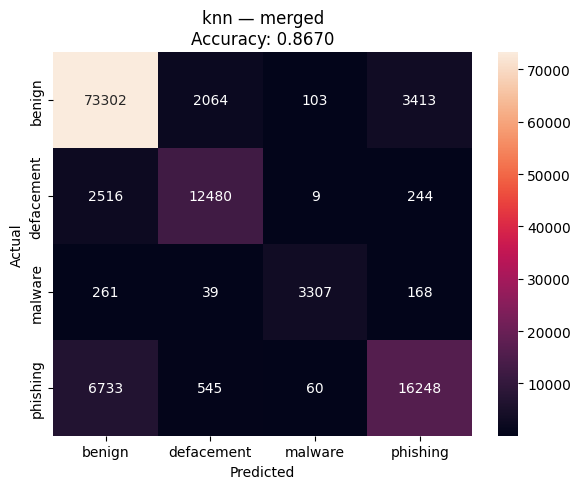

  Saved → merged/knn.pkl


,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",-1
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](4,)","[0,1,2,3]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [6]:
from sklearn.neighbors import KNeighborsClassifier

print("══ MODEL: kNN — Merged ══")

knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
train_evaluate_save(knn, 'knn', 'merged',
                     X_train_scaled, y_train, X_val_scaled, y_val,
                     label_names=LABEL_NAMES)

7. Logistic Regression

- class_weight = 'balanced'

══ MODEL: Logistic Regression (balanced) — Merged ══

  ── merged ──
  Train time : 10.0s
  Accuracy   : 0.5834
  Confusion Matrix:
[[39201 12817  5567 21297]
 [ 1787 12062   175  1225]
 [  209   259  2979   328]
 [ 3639  2161  1153 16633]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.87      0.50      0.63     78882
  defacement       0.44      0.79      0.57     15249
     malware       0.30      0.79      0.44      3775
    phishing       0.42      0.71      0.53     23586

    accuracy                           0.58    121492
   macro avg       0.51      0.70      0.54    121492
weighted avg       0.71      0.58      0.60    121492



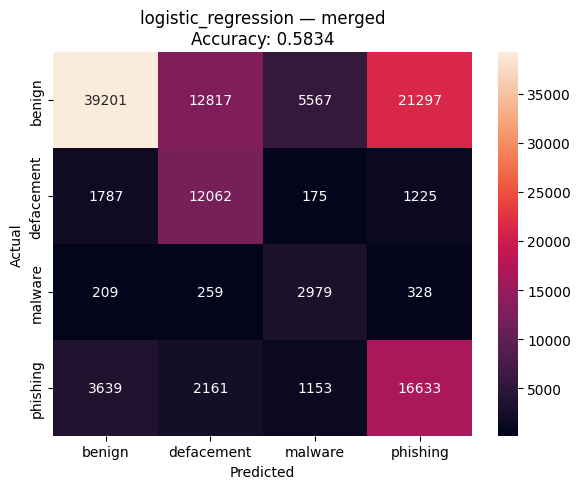

  Saved → merged/logistic_regression.pkl


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"n_jobs n_jobs: int, default=NoneDoes not have any effect... deprecated:: 1.8 `n_jobs` is deprecated in version 1.8 and will be removed in 1.10.",-1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1


In [7]:
from sklearn.linear_model import LogisticRegression

print("══ MODEL: Logistic Regression (balanced) — Merged ══")

lr = LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1, class_weight='balanced')
train_evaluate_save(lr, 'logistic_regression', 'merged',
                     X_train_scaled, y_train, X_val_scaled, y_val,
                     label_names=LABEL_NAMES)

- custom manual class_weight

══ MODEL: Logistic Regression (custom manual) — Merged ══

  ── merged ──
  Train time : 15.1s
  Accuracy   : 0.6899
  Confusion Matrix:
[[57084  3892   467 17439]
 [ 4979  8756     5  1509]
 [  684   108  2486   497]
 [ 7497   481   114 15494]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.81      0.72      0.77     78882
  defacement       0.66      0.57      0.61     15249
     malware       0.81      0.66      0.73      3775
    phishing       0.44      0.66      0.53     23586

    accuracy                           0.69    121492
   macro avg       0.68      0.65      0.66    121492
weighted avg       0.72      0.69      0.70    121492



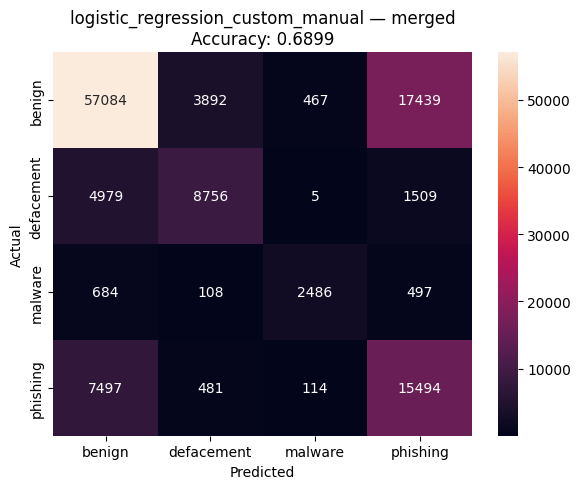

  Saved → merged/logistic_regression_custom_manual.pkl


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*","{0: 1, 1: 2, 2: 4, 3: 2.5}"
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"n_jobs n_jobs: int, default=NoneDoes not have any effect... deprecated:: 1.8 `n_jobs` is deprecated in version 1.8 and will be removed in 1.10.",-1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be inc

In [8]:
print("══ MODEL: Logistic Regression (custom manual) — Merged ══")

custom_manual = {0: 1, 1: 2, 2: 4, 3: 2.5}

lr_custom = LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1, class_weight=custom_manual)
train_evaluate_save(lr_custom, 'logistic_regression_custom_manual', 'merged',
                     X_train_scaled, y_train, X_val_scaled, y_val,
                     label_names=LABEL_NAMES)

8. Decision Tree

══ MODEL: Decision Tree — Merged ══

  ── merged ──
  Train time : 5.6s
  Accuracy   : 0.8318
  Confusion Matrix:
[[75573  1259    94  1956]
 [ 5493  9676     4    76]
 [  596    32  2988   159]
 [10382   324    55 12825]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.82      0.96      0.88     78882
  defacement       0.86      0.63      0.73     15249
     malware       0.95      0.79      0.86      3775
    phishing       0.85      0.54      0.66     23586

    accuracy                           0.83    121492
   macro avg       0.87      0.73      0.79    121492
weighted avg       0.84      0.83      0.82    121492



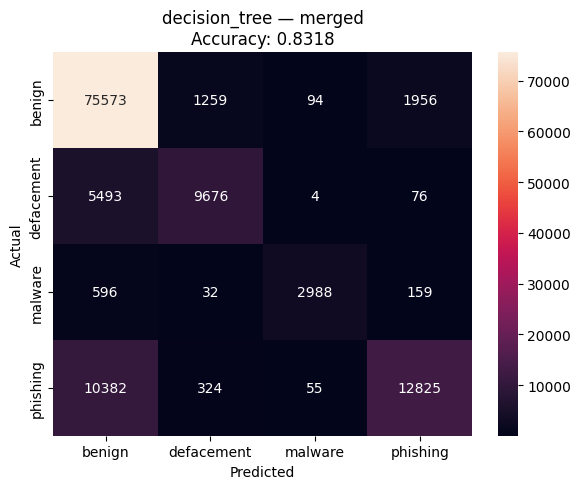

  Saved → merged/decision_tree.pkl


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at

In [9]:
from sklearn.tree import DecisionTreeClassifier

print("══ MODEL: Decision Tree — Merged ══")

dt = DecisionTreeClassifier(max_depth=15, random_state=42)
train_evaluate_save(dt, 'decision_tree', 'merged',
                     X_train, y_train, X_val, y_val,
                     label_names=LABEL_NAMES)

9. SVM (LinearSVC)

══ MODEL: SVM (LinearSVC) — Merged ══

  ── merged ──
  Train time : 124.2s
  Accuracy   : 0.7119
  Confusion Matrix:
[[63661  4749   423 10049]
 [ 5306  9096     5   842]
 [  994   135  2405   241]
 [11035   918   306 11327]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.79      0.81      0.80     78882
  defacement       0.61      0.60      0.60     15249
     malware       0.77      0.64      0.70      3775
    phishing       0.50      0.48      0.49     23586

    accuracy                           0.71    121492
   macro avg       0.67      0.63      0.65    121492
weighted avg       0.71      0.71      0.71    121492



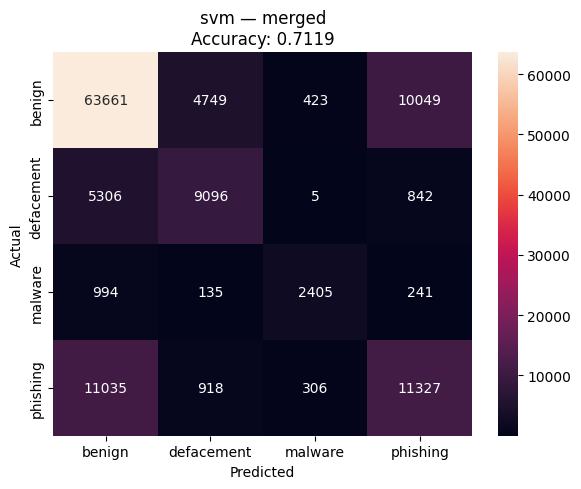

  Saved → merged/svm.pkl


,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forthe dual coordinate descent (if ``dual=True``). When ``dual=False`` theunderlying implementation of :class:`LinearSVC` is not random and``random_state`` has no effect on the results.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_iter max_iter: int, default=1000The maximum number of iterations to be run.",2000
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_

In [10]:
from sklearn.svm import LinearSVC

print("══ MODEL: SVM (LinearSVC) — Merged ══")

svm = LinearSVC(max_iter=2000, random_state=42, dual='auto', class_weight='balanced')
train_evaluate_save(svm, 'svm', 'merged',
                     X_train_scaled, y_train, X_val_scaled, y_val,
                     label_names=LABEL_NAMES)

9.1 SVM Variants Comparison

Subsample Setup

In [11]:
from sklearn.svm import SVC, NuSVC
from sklearn.linear_model import SGDClassifier

# ── Subsample 30K — chỉ dùng cho SVM variants (SVC/NuSVC chậm với data lớn) ──
SUBSAMPLE_SIZE = 30000

train_sub, _ = train_test_split(
    train,
    train_size=SUBSAMPLE_SIZE,
    random_state=42,
    stratify=train['Label']
)

le_sub = LabelEncoder()
X_train_sub        = train_sub[FEATURE_COLS].values
y_train_sub        = le_sub.fit_transform(train_sub['Label'])
X_train_sub_scaled = scaler.transform(X_train_sub)
LABEL_NAMES_SUB    = list(le_sub.classes_)

print(f"Merged subsample : {len(train_sub):,} rows (from {len(train):,} original rows)")
print(f"Val set (full)   : {len(val):,} rows")
print(f"\nLabel distribution (subsample):")
print(train_sub['Label'].value_counts())

Merged subsample : 30,000 rows (from 485,966 original rows)
Val set (full)   : 121,492 rows

Label distribution (subsample):
Label
benign        19478
phishing       5824
defacement     3766
malware         932
Name: count, dtype: int64


SVC (kernel=rbf) — Merged (subsample 30K)

══ SVC (kernel=rbf) — Merged (subsample 30K) ══

  ── merged ──
  Train time : 29.2s
  Accuracy   : 0.7079
  Confusion Matrix:
[[51521 11493  2005 13863]
 [ 1044 13384   122   699]
 [  198   183  3166   228]
 [ 3057  2135   457 17937]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.92      0.65      0.76     78882
  defacement       0.49      0.88      0.63     15249
     malware       0.55      0.84      0.66      3775
    phishing       0.55      0.76      0.64     23586

    accuracy                           0.71    121492
   macro avg       0.63      0.78      0.67    121492
weighted avg       0.78      0.71      0.72    121492



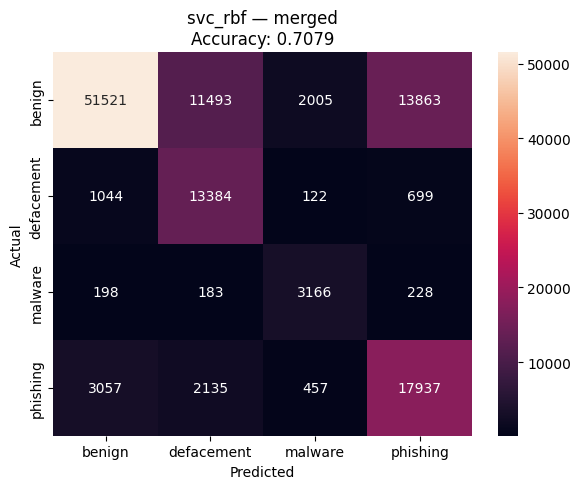

  Saved → merged/svc_rbf.pkl


,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200


In [12]:
print("══ SVC (kernel=rbf) — Merged (subsample 30K) ══")

svc_rbf = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42, class_weight='balanced')
train_evaluate_save(
    svc_rbf, 'svc_rbf', 'merged',
    X_train_sub_scaled, y_train_sub,
    X_val_scaled, y_val,
    label_names=LABEL_NAMES_SUB
)

SVC (kernel=poly) — Merged (subsample 30K)

══ SVC (kernel=poly) — Merged (subsample 30K) ══

  ── merged ──
  Train time : 50.3s
  Accuracy   : 0.7572
  Confusion Matrix:
[[64313  3985   796  9788]
 [ 4662  9627     6   954]
 [  705    82  2761   227]
 [ 7611   488   199 15288]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.83      0.82      0.82     78882
  defacement       0.68      0.63      0.65     15249
     malware       0.73      0.73      0.73      3775
    phishing       0.58      0.65      0.61     23586

    accuracy                           0.76    121492
   macro avg       0.71      0.71      0.71    121492
weighted avg       0.76      0.76      0.76    121492



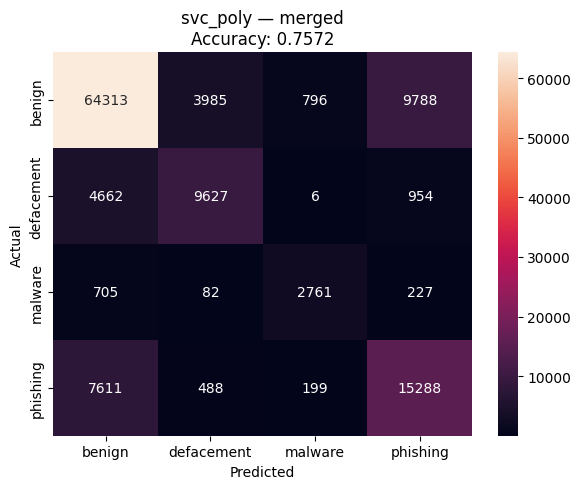

  Saved → merged/svc_poly.pkl


,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'poly'
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200


In [13]:
print("══ SVC (kernel=poly) — Merged (subsample 30K) ══")

svc_poly = SVC(kernel='poly', degree=3, C=1.0, random_state=42, class_weight='balanced')
train_evaluate_save(
    svc_poly, 'svc_poly', 'merged',
    X_train_sub_scaled, y_train_sub,
    X_val_scaled, y_val,
    label_names=LABEL_NAMES_SUB
)

SGDClassifier — Merged (full)

══ SGDClassifier (loss=hinge) — Merged (full data) ══

  ── merged ──
  Train time : 5.2s
  Accuracy   : 0.7197
  Confusion Matrix:
[[65825  4223   508  8326]
 [ 5577  8635    46   991]
 [ 1010   160  2138   467]
 [11577   933   233 10843]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.78      0.83      0.81     78882
  defacement       0.62      0.57      0.59     15249
     malware       0.73      0.57      0.64      3775
    phishing       0.53      0.46      0.49     23586

    accuracy                           0.72    121492
   macro avg       0.66      0.61      0.63    121492
weighted avg       0.71      0.72      0.71    121492



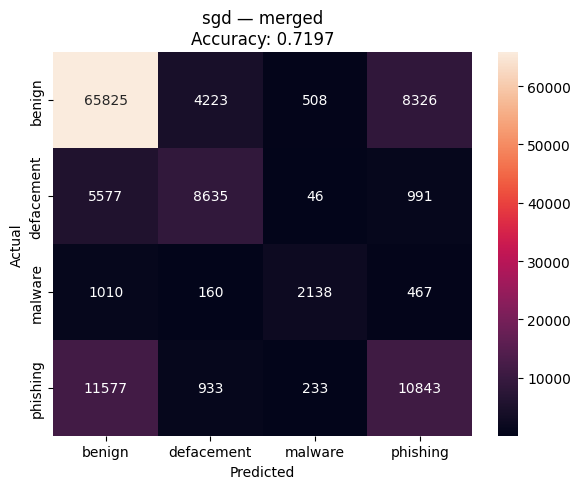

  Saved → merged/sgd.pkl


,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",-1
,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"class_weight class_weight: dict, {class_label: weight} or ""balanced"", default=NonePreset for the class_weight fit parameter.Weights associated with classes. If not given, all classesare supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, 

In [14]:
print("══ SGDClassifier (loss=hinge) — Merged (full data) ══")

sgd = SGDClassifier(
    loss='hinge',
    max_iter=1000,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)
train_evaluate_save(
    sgd, 'sgd', 'merged',
    X_train_scaled, y_train,
    X_val_scaled, y_val,
    label_names=LABEL_NAMES
)

NuSVC — Merged (subsample 30K)

══ NuSVC — Merged (subsample 30K) ══

  ── merged ──
  Train time : 51.3s
  Accuracy   : 0.7715
  Confusion Matrix:
[[66681  2953    86  9162]
 [ 4500 10195    10   544]
 [  572    75  2913   215]
 [ 8664   898    78 13946]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.83      0.85      0.84     78882
  defacement       0.72      0.67      0.69     15249
     malware       0.94      0.77      0.85      3775
    phishing       0.58      0.59      0.59     23586

    accuracy                           0.77    121492
   macro avg       0.77      0.72      0.74    121492
weighted avg       0.77      0.77      0.77    121492



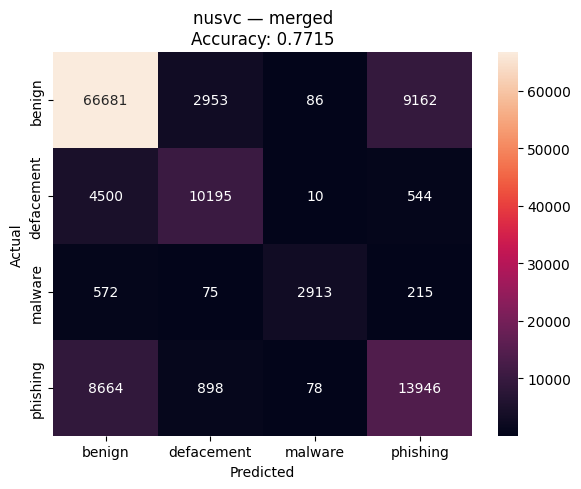

  Saved → merged/nusvc.pkl


,"nu nu: float, default=0.5An upper bound on the fraction of margin errors (see :ref:`User Guide<nu_svc>`) and a lower bound of the fraction of support vectors.Should be in the interval (0, 1].",0.025
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in version 1.11. Use `CalibratedClassifierCV(NuSVC(), ensemble=False)` instead of `NuSVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: {dict, 'balanced'}, default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one. The ""balanced"" mode uses the values of y to automaticallyadjust weights inversely proportional to class frequencies as``n_samples / (n_classes * np.bincount(y))``.",None


In [15]:
print("══ NuSVC — Merged (subsample 30K) ══")

# nu phải < tỉ lệ class nhỏ nhất (malware ~ 3.1%) → dùng nu = 0.025 an toàn
nusvc = NuSVC(nu=0.025, kernel='rbf', random_state=42)
train_evaluate_save(
    nusvc, 'nusvc', 'merged',
    X_train_sub_scaled, y_train_sub,
    X_val_scaled, y_val,
    label_names=LABEL_NAMES_SUB
)

SVM Variants — Summary

In [16]:
svm_keys = [k for k in all_results if any(
    m in k for m in ['svm', 'svc_rbf', 'svc_poly', 'sgd', 'nusvc']
)]

svm_summary = pd.DataFrame([all_results[k] for k in svm_keys])
svm_summary = svm_summary.sort_values(
    ['dataset', 'accuracy'], ascending=[True, False]
).reset_index(drop=True)

print("── SVM Variants Comparison ──\n")
print(svm_summary.to_string(index=False))

svm_path = os.path.join(MODELS_DIR, 'svm_comparison.csv')
svm_summary.to_csv(svm_path, index=False)
print(f"\nExported → svm_comparison.csv")

── SVM Variants Comparison ──

dataset    model  accuracy  train_time
 merged    nusvc    0.7715        51.3
 merged svc_poly    0.7572        50.3
 merged      sgd    0.7197         5.2
 merged      svm    0.7119       124.2
 merged  svc_rbf    0.7079        29.2

Exported → svm_comparison.csv


9.2 Tree-based Variants

LightGBM

══ MODEL: LightGBM — Merged ══

  ── merged ──
  Train time : 8.2s
  Accuracy   : 0.8532
  Confusion Matrix:
[[75458  1023    37  2364]
 [ 4309 10836     5    99]
 [  403    31  3172   169]
 [ 9125   235    33 14193]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.85      0.96      0.90     78882
  defacement       0.89      0.71      0.79     15249
     malware       0.98      0.84      0.90      3775
    phishing       0.84      0.60      0.70     23586

    accuracy                           0.85    121492
   macro avg       0.89      0.78      0.82    121492
weighted avg       0.85      0.85      0.85    121492



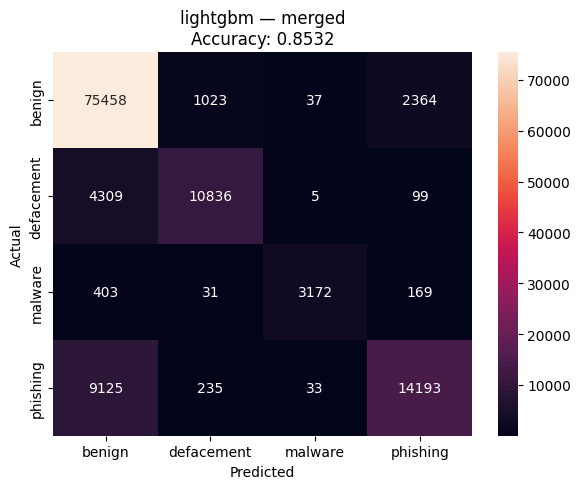

  Saved → merged/lightgbm.pkl


,objective,'multiclass'
,random_state,42
,n_jobs,-1
,num_class,4
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000


In [17]:
from lightgbm import LGBMClassifier

print("══ MODEL: LightGBM — Merged ══")

lgbm = LGBMClassifier(
    objective='multiclass',
    num_class=4,
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
train_evaluate_save(lgbm, 'lightgbm', 'merged',
                     X_train, y_train, X_val, y_val,
                     label_names=LABEL_NAMES)

ExtraTreesClassifier

══ MODEL: ExtraTrees — Merged ══

  ── merged ──
  Train time : 13.3s
  Accuracy   : 0.7981
  Confusion Matrix:
[[63675  4312    90 10805]
 [ 2334 11598    11  1306]
 [  281    71  3190   233]
 [ 4456   579    50 18501]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.90      0.81      0.85     78882
  defacement       0.70      0.76      0.73     15249
     malware       0.95      0.85      0.90      3775
    phishing       0.60      0.78      0.68     23586

    accuracy                           0.80    121492
   macro avg       0.79      0.80      0.79    121492
weighted avg       0.82      0.80      0.80    121492



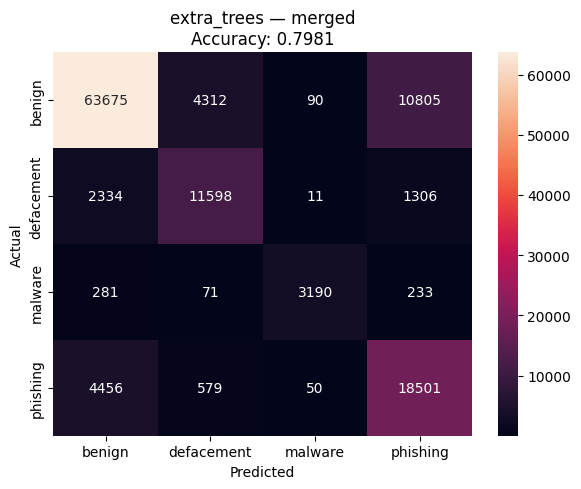

  Saved → merged/extra_trees.pkl


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls 3 sources of randomness:- the bootstrapping of the samples used when building trees (if ``bootstrap=True``)- the sampling of the features to consider when looking for the best split at each node (if ``max_features < n_features``)- the draw of the splits for each of the `max_features`See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when loo

In [18]:
from sklearn.ensemble import ExtraTreesClassifier

print("══ MODEL: ExtraTrees — Merged ══")

et = ExtraTreesClassifier(n_estimators=100, max_depth=20,
                           random_state=42, n_jobs=-1, class_weight='balanced')
train_evaluate_save(et, 'extra_trees', 'merged',
                     X_train, y_train, X_val, y_val,
                     label_names=LABEL_NAMES)

BaggingClassifier

══ MODEL: Bagging — Merged ══

  ── merged ──
  Train time : 96.6s
  Accuracy   : 0.8677
  Confusion Matrix:
[[76089   924    15  1854]
 [ 3717 11401     1   130]
 [  468    27  3130   150]
 [ 8472   291    29 14794]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.86      0.96      0.91     78882
  defacement       0.90      0.75      0.82     15249
     malware       0.99      0.83      0.90      3775
    phishing       0.87      0.63      0.73     23586

    accuracy                           0.87    121492
   macro avg       0.90      0.79      0.84    121492
weighted avg       0.87      0.87      0.86    121492



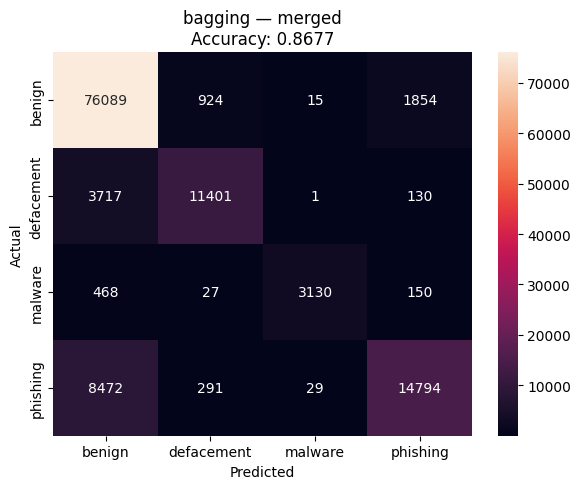

  Saved → merged/bagging.pkl


,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...ndom_state=42)
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",100
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",None
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",1.0
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",True
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary <warm_start>`... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


In [19]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

print("══ MODEL: Bagging — Merged ══")

bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=20, random_state=42),
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
train_evaluate_save(bag, 'bagging', 'merged',
                     X_train, y_train, X_val, y_val,
                     label_names=LABEL_NAMES)

AdaBoostClassifier

══ MODEL: AdaBoost — Merged ══

  ── merged ──
  Train time : 64.9s
  Accuracy   : 0.7348
  Confusion Matrix:
[[73634   950     3  4295]
 [ 9585  5553     0   111]
 [ 1684    31  1868   192]
 [15134   213    26  8213]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.74      0.93      0.82     78882
  defacement       0.82      0.36      0.50     15249
     malware       0.98      0.49      0.66      3775
    phishing       0.64      0.35      0.45     23586

    accuracy                           0.73    121492
   macro avg       0.80      0.54      0.61    121492
weighted avg       0.74      0.73      0.71    121492



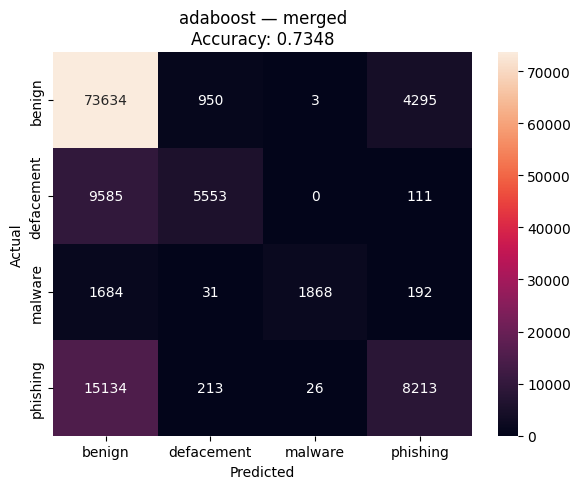

  Saved → merged/adaboost.pkl


,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",100
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](4,)","[0,1,2,3]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](100,)","[0.32,0.54,0.58,...,0.73,0.73,0.74]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](100,)","[1.86,0.93,0.76,...,0.11,0.1 ,0.05]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1608637542), DecisionTreeC...te=1273642419), DecisionTreeC...te=1935803228), DecisionTreeC...ate=787846414), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](32,)","[0.01,0. ,0.08,...,0.04,0.01,0. ]"


In [20]:
from sklearn.ensemble import AdaBoostClassifier

print("══ MODEL: AdaBoost — Merged ══")

ada = AdaBoostClassifier(
    n_estimators=100,
    random_state=42
)
train_evaluate_save(ada, 'adaboost', 'merged',
                     X_train, y_train, X_val, y_val,
                     label_names=LABEL_NAMES)

GradientBoostingClassifier

══ MODEL: GradientBoosting — Merged ══

  ── merged ──
  Train time : 618.4s
  Accuracy   : 0.8104
  Confusion Matrix:
[[76339   748     5  1790]
 [ 7009  8073     0   167]
 [  896    32  2651   196]
 [12085    79    29 11393]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.79      0.97      0.87     78882
  defacement       0.90      0.53      0.67     15249
     malware       0.99      0.70      0.82      3775
    phishing       0.84      0.48      0.61     23586

    accuracy                           0.81    121492
   macro avg       0.88      0.67      0.74    121492
weighted avg       0.82      0.81      0.79    121492



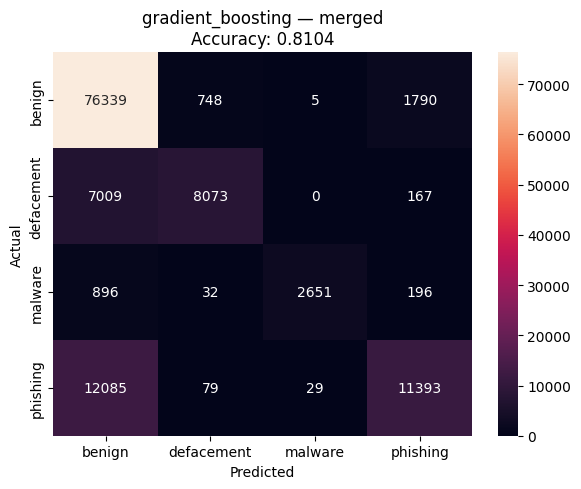

  Saved → merged/gradient_boosting.pkl


,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [21]:
from sklearn.ensemble import GradientBoostingClassifier

print("══ MODEL: GradientBoosting — Merged ══")

gb = GradientBoostingClassifier(
    n_estimators=100,
    random_state=42
)
train_evaluate_save(gb, 'gradient_boosting', 'merged',
                     X_train, y_train, X_val, y_val,
                     label_names=LABEL_NAMES)

10. Random Forest

══ MODEL: Random Forest — Merged ══

  ── merged ──
  Train time : 16.6s
  Accuracy   : 0.8687
  Confusion Matrix:
[[77053   416     3  1410]
 [ 4255 10927     0    67]
 [  490    21  3128   136]
 [ 9004   128    17 14437]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.85      0.98      0.91     78882
  defacement       0.95      0.72      0.82     15249
     malware       0.99      0.83      0.90      3775
    phishing       0.90      0.61      0.73     23586

    accuracy                           0.87    121492
   macro avg       0.92      0.78      0.84    121492
weighted avg       0.88      0.87      0.86    121492



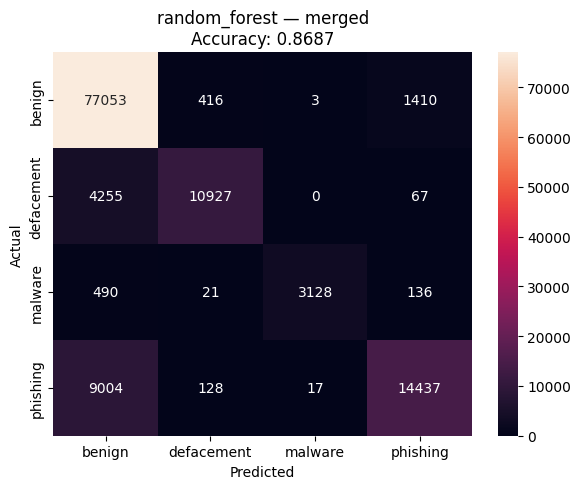

  Saved → merged/random_forest.pkl


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

In [22]:
from sklearn.ensemble import RandomForestClassifier

print("══ MODEL: Random Forest — Merged ══")

rf = RandomForestClassifier(n_estimators=100, max_depth=20,
                              random_state=42, n_jobs=-1)
train_evaluate_save(rf, 'random_forest', 'merged',
                     X_train, y_train, X_val, y_val,
                     label_names=LABEL_NAMES)

11. XGBoost

══ MODEL: XGBoost — Merged ══

  ── merged ──
  Train time : 10.2s
  Accuracy   : 0.8572
  Confusion Matrix:
[[76129   750    13  1990]
 [ 4607 10544     1    97]
 [  410    29  3179   157]
 [ 9089   188    23 14286]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.84      0.97      0.90     78882
  defacement       0.92      0.69      0.79     15249
     malware       0.99      0.84      0.91      3775
    phishing       0.86      0.61      0.71     23586

    accuracy                           0.86    121492
   macro avg       0.90      0.78      0.83    121492
weighted avg       0.86      0.86      0.85    121492



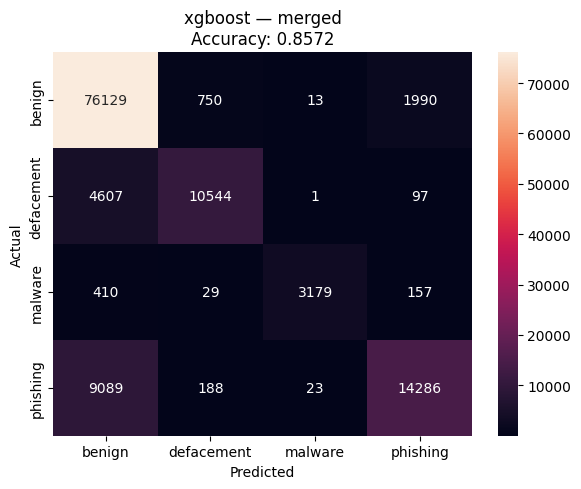

  Saved → merged/xgboost.pkl


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import lo

In [23]:
from xgboost import XGBClassifier

print("══ MODEL: XGBoost — Merged ══")

xgb = XGBClassifier(n_estimators=100, max_depth=8, learning_rate=0.1,
                      random_state=42, eval_metric='mlogloss',
                      n_jobs=-1, verbosity=0)
train_evaluate_save(xgb, 'xgboost', 'merged',
                     X_train, y_train, X_val, y_val,
                     label_names=LABEL_NAMES)

12. Comparison Summary

In [24]:
summary = pd.DataFrame(all_results.values())
summary = summary.sort_values(['dataset', 'accuracy'], ascending=[True, False])

print("── Model Comparison Summary (Merged Dataset) ──\n")
print(summary.to_string(index=False))

summary_path = os.path.join(MODELS_DIR, 'model_comparison.csv')
summary.to_csv(summary_path, index=False)
print(f"\nExported → {os.path.basename(summary_path)}")

── Model Comparison Summary (Merged Dataset) ──

dataset                             model  accuracy  train_time
 merged                     random_forest    0.8687        16.6
 merged                           bagging    0.8677        96.6
 merged                               knn    0.8670         0.1
 merged                           xgboost    0.8572        10.2
 merged                          lightgbm    0.8532         8.2
 merged                     decision_tree    0.8318         5.6
 merged                 gradient_boosting    0.8104       618.4
 merged                       extra_trees    0.7981        13.3
 merged                             nusvc    0.7715        51.3
 merged                          svc_poly    0.7572        50.3
 merged                          adaboost    0.7348        64.9
 merged                               sgd    0.7197         5.2
 merged                               svm    0.7119       124.2
 merged                           svc_rbf    0.7079    

13. Error Analysis (Merged Dataset)

13.1 Load Predictions from All Trained Models

In [25]:
# Load lại toàn bộ model đã train (.pkl), predict trên val set
# để có ma trận dự đoán của tất cả model — phục vụ phân tích lỗi tổng hợp

SCALED_MODELS = {
    'knn', 'svm', 'svc_rbf', 'svc_poly', 'nusvc', 'sgd',
    'logistic_regression', 'logistic_regression_custom_manual'
}

model_keys = sorted([info['model'] for k, info in all_results.items()
                     if info['dataset'] == 'merged'])

predictions = {}
for model_key in model_keys:
    model_path = os.path.join(MODELS_DIR, 'merged', f'{model_key}.pkl')
    model = joblib.load(model_path)
    X_input = X_val_scaled if model_key in SCALED_MODELS else X_val
    predictions[model_key] = model.predict(X_input)

print(f"Loaded predictions for {len(predictions)} models (Merged):")
print(list(predictions.keys()))

Loaded predictions for 16 models (Merged):
['adaboost', 'bagging', 'decision_tree', 'extra_trees', 'gradient_boosting', 'knn', 'lightgbm', 'logistic_regression', 'logistic_regression_custom_manual', 'nusvc', 'random_forest', 'sgd', 'svc_poly', 'svc_rbf', 'svm', 'xgboost']


13.2 Identify "Hard Cases" — Samples Misclassified by Most Models

In [26]:
# Với mỗi sample trong val set, đếm xem có bao nhiêu model (trong tổng số N model) đoán sai
pred_matrix = np.column_stack(list(predictions.values()))  # shape (n_val, n_models)
model_names_order = list(predictions.keys())
n_models_total = len(model_names_order)

is_wrong = pred_matrix != y_val[:, None]
n_wrong_per_sample = is_wrong.sum(axis=1)

val_analysis = val.copy()
val_analysis['n_models_wrong'] = n_wrong_per_sample
val_analysis['n_models_total'] = n_models_total
val_analysis['pct_models_wrong'] = (n_wrong_per_sample / n_models_total * 100).round(1)

print("── Distribution of Misclassifying Models per Sample (Merged Val Set) ──")
print(val_analysis['n_models_wrong'].value_counts().sort_index())

# Hard cases: bị từ 70% model trở lên đoán sai
threshold = 0.7
hard_cases = val_analysis[val_analysis['n_models_wrong'] >= n_models_total * threshold]
print(f"\n{len(hard_cases)} samples misclassified by >= {int(threshold*100)}% of models ({int(n_models_total*threshold)}/{n_models_total})")
print(f"Percentage of val set: {len(hard_cases)/len(val_analysis)*100:.2f}%")

print("\nLabel distribution of hard cases:")
print(hard_cases['Label'].value_counts())

── Distribution of Misclassifying Models per Sample (Merged Val Set) ──
n_models_wrong
0     40317
1     18022
2     11695
3      8308
4      6248
5      5742
6      4882
7      4653
8      4030
9      2718
10     2314
11     1942
12     1888
13     1900
14     1972
15     2173
16     2688
Name: count, dtype: int64

10621 samples misclassified by >= 70% of models (11/16)
Percentage of val set: 8.74%

Label distribution of hard cases:
Label
phishing      5717
defacement    3164
benign        1143
malware        597
Name: count, dtype: int64


13.3 Most Common Confusion Pairs (Aggregated Across All Models)

── Top 10 Confusion Pairs (Aggregated Across All 16 Models, Merged) ──
true_label pred_label  count
  phishing     benign 137560
    benign   phishing 119801
defacement     benign  71680
    benign defacement  56558
  phishing defacement  10596
    benign    malware  10215
   malware     benign   9861
defacement   phishing   9061
   malware   phishing   3763
  phishing    malware   2862


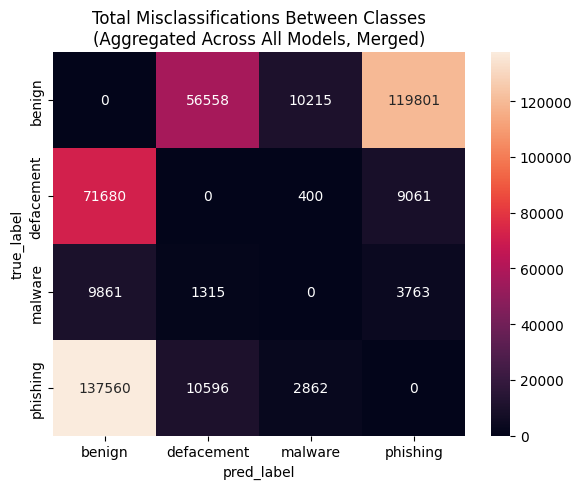

In [27]:
from collections import Counter

# Đếm tần suất các cặp (nhãn thật, nhãn đoán) bị sai, tổng hợp qua TẤT CẢ model
pair_counter = Counter()
for model_key, y_pred in predictions.items():
    wrong_mask = y_pred != y_val
    true_wrong = y_val[wrong_mask]
    pred_wrong = y_pred[wrong_mask]
    for t, p in zip(true_wrong, pred_wrong):
        pair_counter[(LABEL_NAMES[t], LABEL_NAMES[p])] += 1

pair_df = pd.DataFrame(
    [(t, p, c) for (t, p), c in pair_counter.items()],
    columns=['true_label', 'pred_label', 'count']
).sort_values('count', ascending=False).reset_index(drop=True)

print("── Top 10 Confusion Pairs (Aggregated Across All 16 Models, Merged) ──")
print(pair_df.head(10).to_string(index=False))

# Heatmap trực quan các cặp nhầm lẫn
pivot = pair_df.pivot_table(index='true_label', columns='pred_label', values='count', fill_value=0)
plt.figure(figsize=(6, 5))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='rocket')
plt.title('Total Misclassifications Between Classes\n(Aggregated Across All Models, Merged)')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '..', 'error_analysis_confusion_pairs.png'), dpi=150)
plt.show()

13.4 Feature Distribution by Sample Difficulty

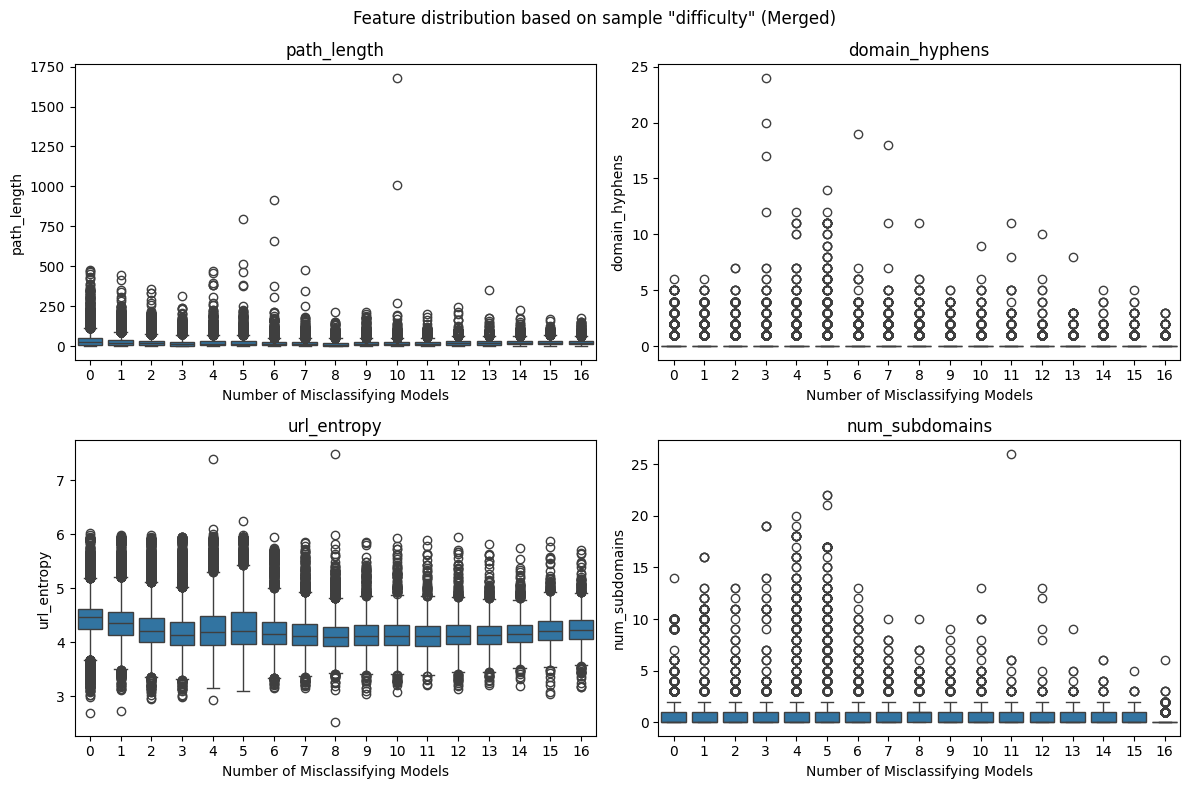

In [28]:
top_features = ['path_length', 'domain_hyphens', 'url_entropy', 'num_subdomains']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feat in zip(axes.flatten(), top_features):
    sns.boxplot(data=val_analysis, x='n_models_wrong', y=feat, ax=ax)
    ax.set_title(feat)
    ax.set_xlabel('Number of Misclassifying Models')

plt.suptitle('Feature distribution based on sample "difficulty" (Merged)')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '..', 'error_analysis_feature_distribution.png'), dpi=150)
plt.show()

13.5 Inspect Representative Hard Case URLs & Export

In [29]:
# In ra URL thực tế của 20 hard cases bị nhiều model đoán sai nhất — để xem thủ công
print("── Top 20 Representative Hard Cases (Merged) ──\n")
top_hard = val_analysis.sort_values('n_models_wrong', ascending=False).head(20)
for _, row in top_hard.iterrows():
    print(f"[{row['n_models_wrong']}/{row['n_models_total']} models wrong] True={row['Label']:12s} | {row['URL'][:90]}")

# Export toàn bộ hard cases ra CSV để phân tích/nộp báo cáo
hard_cases_export = hard_cases[['URL', 'Label', 'n_models_wrong', 'n_models_total', 'pct_models_wrong'] + FEATURE_COLS]
export_path = os.path.join(MODELS_DIR, 'hard_cases_merged.csv')
hard_cases_export.to_csv(export_path, index=False)
print(f"\nExported {len(hard_cases_export)} hard cases → {os.path.basename(export_path)}")

── Top 20 Representative Hard Cases (Merged) ──

[16/16 models wrong] True=phishing     | http://breathofair.co.uk/ASP/applications/Tv_guide/
[16/16 models wrong] True=defacement   | http://paradigmafcm.com/es/e-news/oct-2010
[16/16 models wrong] True=phishing     | http://weblogs.java.net/blog/monsonhaefel/archive/2004/03/jsr241_groovy_a.html
[16/16 models wrong] True=malware      | http://johukumprice.com
[16/16 models wrong] True=phishing     | http://nps.gov/jame/historyculture/flax-production-in-the-seventeenth-century.htm
[16/16 models wrong] True=phishing     | http://crx.pai.mybluehost.me/website_606f33fa/CDCORREOS/auth/index.php
[16/16 models wrong] True=defacement   | http://schighway.co.kr/homepage/contents/sc_sub1/qualification.asp
[16/16 models wrong] True=defacement   | http://copremon.com.br/emprestimos.html
[16/16 models wrong] True=phishing     | http://rozalli.com.ua/APAP/Asociacion_Popular/APAP/
[16/16 models wrong] True=phishing     | http://inmobiliariasanmarcos.co